In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pathlib import Path
from sklearn.metrics import *
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torchvision import transforms

In [10]:
import requests
import os
from zipfile import ZipFile

data_path = Path('/home/23bq1a4293/Personal/project/Classification_Data')
data_path

PosixPath('/home/23bq1a4293/Personal/project/Classification_Data')

In [11]:
def data_stats(data_path: Path):
    print(list(os.walk(data_path)))

    print("Directory name",data_path.stem)

    print("sub folders ",','.join(list(os.walk(data_path))[0][1]))

    for directory_stats in os.walk(data_path):
        print(f"Directory: {directory_stats[0]} ->  `{len(directory_stats[1])}` sub-directories |  `{len(directory_stats[2])}` files")
    
data_stats(data_path)

[('/home/23bq1a4293/Personal/project/Classification_Data', ['Testing', 'Training'], []), ('/home/23bq1a4293/Personal/project/Classification_Data/Testing', ['meningioma', 'notumor', 'glioma', 'pituitary'], []), ('/home/23bq1a4293/Personal/project/Classification_Data/Testing/meningioma', [], ['Te-me_0102.jpg', 'Te-me_0014.jpg', 'Te-me_0295.jpg', 'Te-me_0188.jpg', 'Te-me_0204.jpg', 'Te-me_0128.jpg', 'Te-me_0301.jpg', 'Te-me_0164.jpg', 'Te-me_0123.jpg', 'Te-me_0010.jpg', 'Te-me_0247.jpg', 'Te-me_0196.jpg', 'Te-me_0227.jpg', 'Te-me_0029.jpg', 'Te-me_0119.jpg', 'Te-me_0064.jpg', 'Te-me_0186.jpg', 'Te-me_0278.jpg', 'Te-me_0174.jpg', 'Te-me_0091.jpg', 'Te-me_0054.jpg', 'Te-me_0143.jpg', 'Te-me_0213.jpg', 'Te-me_0263.jpg', 'Te-meTr_0002.jpg', 'Te-me_0031.jpg', 'Te-me_0109.jpg', 'Te-me_0172.jpg', 'Te-me_0059.jpg', 'Te-me_0150.jpg', 'Te-me_0022.jpg', 'Te-me_0209.jpg', 'Te-me_0270.jpg', 'Te-me_0184.jpg', 'Te-me_0092.jpg', 'Te-me_0171.jpg', 'Te-me_0246.jpg', 'Te-me_0026.jpg', 'Te-me_0226.jpg', 'Te-

In [12]:
#path for training data
train_dir =data_path/'Training'
#path for testing data
test_dir =data_path/'Testing'

train_dir,test_dir

(PosixPath('/home/23bq1a4293/Personal/project/Classification_Data/Training'),
 PosixPath('/home/23bq1a4293/Personal/project/Classification_Data/Testing'))

In [13]:
train_imgs =list(train_dir.glob('*/*.jpg'))

print(f"no of training samples: {len(train_imgs)}")

no of training samples: 5712


Text(0.5, 1.0, 'glioma')

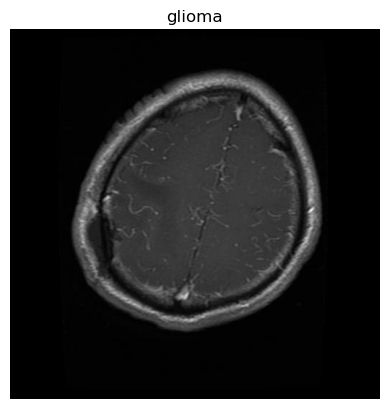

In [14]:
import random

#visualizing the image

random_img_path =random.choice(train_imgs)
random_img =Image.open(random_img_path)

plt.imshow(random_img ,cmap='grey')
plt.axis(False)
plt.title(random_img_path.parent.stem)

In [58]:
train_data = ImageFolder(
    root = train_dir,
    transform=transforms.Compose([
        transforms.Resize((64,64)),
        transforms.ToTensor()
    ])
)

train_data

Dataset ImageFolder
    Number of datapoints: 5712
    Root location: /home/23bq1a4293/Personal/project/Classification_Data/Training
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )

In [59]:
len(train_data),train_data[0][0].shape

(5712, torch.Size([3, 64, 64]))

In [60]:
test_data =ImageFolder(
    root =test_dir,
    transform =transforms.Compose([
        transforms.Resize((64,64)),
        transforms.ToTensor()
    ])
)

test_data

Dataset ImageFolder
    Number of datapoints: 1311
    Root location: /home/23bq1a4293/Personal/project/Classification_Data/Testing
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )

In [61]:
len(test_data)

1311

In [62]:
img,label=train_data[0]
label

0

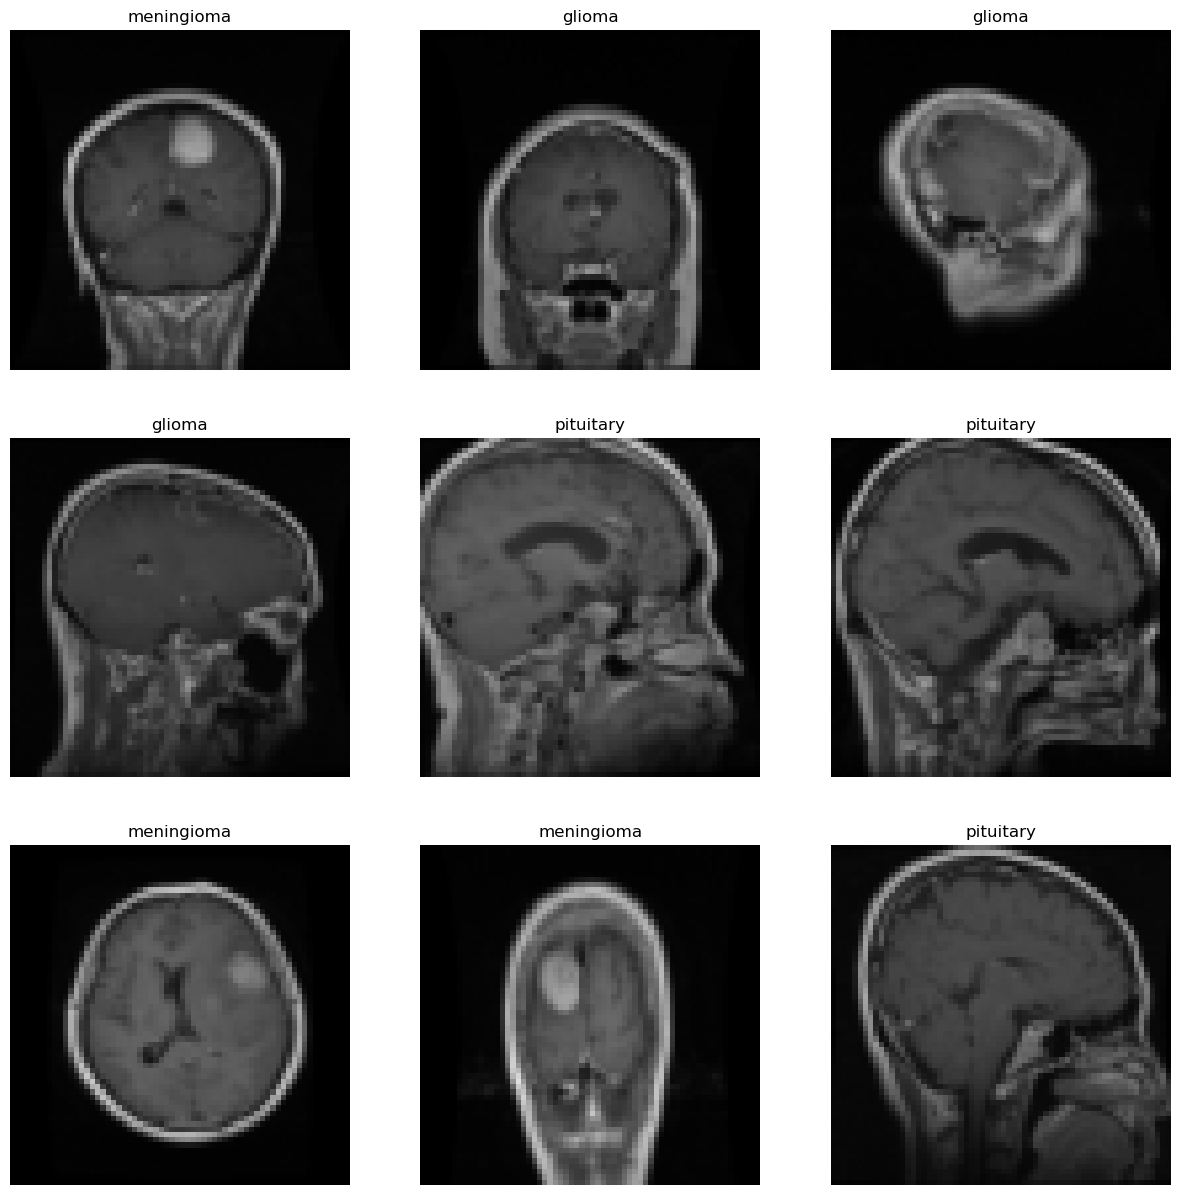

In [63]:
nrows = 3
ncols = 3
fig =plt.figure(figsize=(15,15))

for i in range(1, nrows*ncols+1):
    random_idx = torch.randint(low=0,high =len(train_data),size=[1]).item()
    img,label =train_data[random_idx]

    fig.add_subplot(nrows,ncols,i)
    plt.title(train_data.classes[label])
    plt.axis(False)
    plt.imshow((img.permute(1, 2, 0)))

In [64]:
train_data_loader=DataLoader(
    dataset =train_data,
    batch_size=32,
    shuffle=True
)

train_data_loader

In [65]:
test_data_loader=DataLoader(
    dataset=test_data,
    batch_size=32,
    shuffle=True
)

test_data_loader

In [66]:
print(img)
print(train_data.classes[label])

tensor([[[0.0118, 0.0118, 0.0078,  ..., 0.0078, 0.0078, 0.0039],
         [0.0235, 0.0235, 0.0235,  ..., 0.0235, 0.0235, 0.0196],
         [0.0275, 0.0275, 0.0275,  ..., 0.0314, 0.0275, 0.0235],
         ...,
         [0.0235, 0.0235, 0.0275,  ..., 0.0431, 0.0431, 0.0392],
         [0.0235, 0.0275, 0.0275,  ..., 0.0392, 0.0353, 0.0353],
         [0.0078, 0.0118, 0.0157,  ..., 0.0157, 0.0118, 0.0118]],

        [[0.0118, 0.0118, 0.0078,  ..., 0.0078, 0.0078, 0.0039],
         [0.0235, 0.0235, 0.0235,  ..., 0.0235, 0.0235, 0.0196],
         [0.0275, 0.0275, 0.0275,  ..., 0.0314, 0.0275, 0.0235],
         ...,
         [0.0235, 0.0235, 0.0275,  ..., 0.0431, 0.0431, 0.0392],
         [0.0235, 0.0275, 0.0275,  ..., 0.0392, 0.0353, 0.0353],
         [0.0078, 0.0118, 0.0157,  ..., 0.0157, 0.0118, 0.0118]],

        [[0.0118, 0.0118, 0.0078,  ..., 0.0078, 0.0078, 0.0039],
         [0.0235, 0.0235, 0.0235,  ..., 0.0235, 0.0235, 0.0196],
         [0.0275, 0.0275, 0.0275,  ..., 0.0314, 0.0275, 0.

In [67]:
len(train_data_loader),len(test_data_loader)

(179, 41)

In [68]:
device =torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [69]:
def accuracy(y_true: torch.Tensor, y_pred:torch.Tensor)->float:
    y_pred_cpu = y_pred.cpu()
    y_pred_class = torch.argmax(y_pred_cpu, dim=1)
    correct = (y_true.cpu() == y_pred_class).sum().item()
    total = y_true.size(0)
    return correct / total * 100

In [70]:
import torch
import torch.nn as nn

class BT(nn.Module):
    def __init__(self, in_features=3, hidden_features=512, out_features=4):
        super(BT, self).__init__()

        self.model = nn.Sequential(
            # -------- Layer 1: 64x64 -> 32x32 --------
            nn.Conv2d(in_features, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), # Stabilizes training
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # -------- Layer 2: 32x32 -> 16x16 --------
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # -------- Layer 3: 16x16 -> 8x8 --------
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # -------- Classification Head --------
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, hidden_features),
            nn.ReLU(),
            nn.Dropout(0.4), # Slightly lower dropout helps learning start faster
            nn.Linear(hidden_features, out_features)
        )

    def forward(self, x):
        return self.model(x)

# Initialize the new model
model0 = BT(in_features=3, hidden_features=512, out_features=4).to(device)

In [71]:
loss = nn.CrossEntropyLoss()

In [72]:
optimizer = torch.optim.Adam(
    model0.parameters(),
    lr=0.0001
)

In [73]:
from tqdm.auto import tqdm 
def train_model(model, train_loader, criterion, optimizer, epochs=10):
    model.train()

    for epoch in tqdm(range(epochs)):
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            # 1. Clear old gradients
            optimizer.zero_grad()

            # 2. Forward pass
            outputs = model(images)

            # 3. Compute loss
            loss = criterion(outputs, labels)

            # 4. Backpropagation
            loss.backward()

            # 5. Update weights
            optimizer.step()

            running_loss += loss.item()

            # Accuracy calculation
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader)
        epoch_acc = 100 * correct / total

        print(f"Epoch [{epoch+1}/{epochs}] "
              f"Loss: {epoch_loss:.4f} "
              f"Accuracy: {epoch_acc:.2f}%")


In [74]:
train_model(model0, train_data_loader, loss, optimizer, epochs=12)
model_save_path = "/home/23bq1a4293/Personal/project/models/Classification/bt_classifier.pth"
torch.save(model0.state_dict(), model_save_path)
print(f"✅ Model saved to {model_save_path}")

  0%|          | 0/12 [00:00<?, ?it/s]

Epoch [1/12] Loss: 0.6193 Accuracy: 75.16%
Epoch [2/12] Loss: 0.3954 Accuracy: 85.17%
Epoch [3/12] Loss: 0.2976 Accuracy: 88.76%
Epoch [4/12] Loss: 0.2444 Accuracy: 90.42%
Epoch [5/12] Loss: 0.1898 Accuracy: 93.45%
Epoch [6/12] Loss: 0.1600 Accuracy: 94.12%
Epoch [7/12] Loss: 0.1440 Accuracy: 94.75%
Epoch [8/12] Loss: 0.0900 Accuracy: 97.22%
Epoch [9/12] Loss: 0.0905 Accuracy: 96.85%
Epoch [10/12] Loss: 0.0642 Accuracy: 98.06%
Epoch [11/12] Loss: 0.0501 Accuracy: 98.53%
Epoch [12/12] Loss: 0.0421 Accuracy: 98.76%
✅ Model saved to /home/23bq1a4293/Personal/project/models/Classification/bt_classifier.pth


In [75]:
def evaluate_model(model, test_loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {100 * correct / total:.2f}%")


In [76]:
evaluate_model(model0,test_data_loader)

Test Accuracy: 95.58%


In [78]:
import random
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample)
    test_labels.append(label)

In [79]:
def make_predictions(
    model: torch.nn.Module,
    data: list,
    device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
):
    pred_probs = []

    model.to(device)
    model.eval()

    with torch.inference_mode():
        for sample in data:
            sample = sample.unsqueeze(0).to(device)

            logits = model(sample)
            probs = torch.softmax(logits.squeeze(), dim=0)

            pred_probs.append(probs.cpu())

    return torch.stack(pred_probs)


In [80]:
pred_probs = make_predictions(model0, test_samples)
pred_classes = pred_probs.argmax(dim=1)

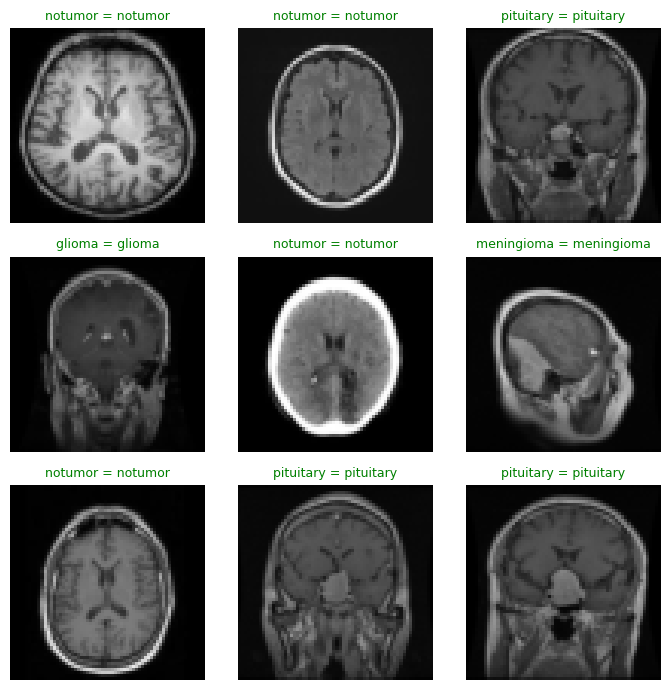

In [81]:
import matplotlib.pyplot as plt
import random
import numpy as np

nrows, ncols = 3, 3
num_images = nrows * ncols

# Random indices
indices = random.sample(range(len(test_samples)), num_images)

fig = plt.figure(figsize=(7, 7))

for i, idx in enumerate(indices, start=1):
    img = test_samples[idx].cpu()

    # Handle grayscale or RGB
    if img.shape[0] == 1:
        img = img.squeeze()
        cmap = "gray"
    else:
        img = np.transpose(img.numpy(), (1, 2, 0))
        cmap = None

    true_label = test_labels[idx]
    pred_label = pred_classes[idx]

    fig.add_subplot(nrows, ncols, i)
    plt.axis("off")

    color = "green" if true_label == pred_label else "red"
    symbol = "=" if true_label == pred_label else "≠"

    plt.title(
        f"{test_data.classes[true_label]} {symbol} {test_data.classes[pred_label]}",
        color=color,
        fontsize=9
    )

    plt.imshow(img, cmap=cmap)

plt.tight_layout()
plt.show()


In [94]:
import nibabel as nib
import torch
import numpy as np
from PIL import Image
from torchvision import transforms

def predict_nifti(model, nifti_path, device):
    # 1. Load NIfTI 
    img = nib.load(nifti_path)
    data = img.get_fdata()
    
    # --- IMPROVED SLICE SELECTION (Variance Method) ---
    # Instead of intensity sum, we look for the slice with the highest variance.
    # This avoids blank/noisy slices and finds the one with the most anatomical detail.
    slice_variances = [np.var(data[:, :, i]) for i in range(data.shape[2])]
    best_slice_idx = np.argmax(slice_variances)
    slice_2d = data[:, :, best_slice_idx]

    # --- IMPROVED NORMALIZATION (Robust Scaling) ---
    # 1. Clip the top 1% of intensities to remove noise/bright bone artifacts
    upper_limit = np.percentile(slice_2d, 99)
    slice_2d = np.clip(slice_2d, 0, upper_limit)
    
    # 2. Scale to 0-255 for standard image processing
    slice_min = np.min(slice_2d)
    slice_max = np.max(slice_2d)
    slice_2d = (slice_2d - slice_min) / (slice_max - slice_min + 1e-8)
    slice_2d = (slice_2d * 255).astype(np.uint8)
    
    # 2. Convert to PIL and then to RGB to match in_features=3
    img_pil = Image.fromarray(slice_2d).convert("RGB")

    # 3. Apply your specific training transforms (Matching your 64x64 training)
    preprocess = transforms.Compose([
        transforms.Resize((64, 64)), 
        transforms.ToTensor()        
    ])
    
    input_tensor = preprocess(img_pil).unsqueeze(0).to(device)

    # 4. Model Prediction
    model.eval()
    with torch.no_grad():
        logits = model(input_tensor)
        probs = torch.softmax(logits, dim=1)
        pred_class = torch.argmax(probs, dim=1).item()
    
    # Ensure test_data is defined in your environment or pass classes as an argument
    return {
        "label": test_data.classes[pred_class],
        "confidence": float(torch.max(probs)),
        "slice_used": int(best_slice_idx)
    }

In [106]:
import nibabel as nib
import numpy as np
import torch
from PIL import Image
from torchvision import transforms

def make_nifti_prediction(model, nifti_path, device, class_names):
    model.eval()
    
    # 1. Load NIfTI and Data
    img = nib.load(nifti_path)
    data = img.get_fdata()
    
    # 2. Slice Selection Strategy: Most "Abnormal" Slice
    # We find the slice that deviates most from the average brain structure
    avg_brain = np.mean(data, axis=2)
    
    # Calculate difference for every slice
    diffs = [np.sum(np.abs(data[:, :, i] - avg_brain)) for i in range(data.shape[2])]
    
    # Apply 20% margin to avoid empty top/bottom slices
    margin = int(len(diffs) * 0.2)
    # Find max difference within the middle 60% of the scan
    best_idx = np.argmax(diffs[margin:-margin]) + margin
    slice_2d = data[:, :, best_idx]

    # 3. Robust Normalization
    # Clipping at 1st and 99th percentile removes noise and bright bone artifacts
    p1, p99 = np.percentile(slice_2d, [1, 99])
    slice_2d = np.clip(slice_2d, p1, p99)
    slice_2d = (slice_2d - p1) / (p99 - p1 + 1e-8)
    
    # 4. Convert to 3-Channel RGB (Matches BT Model's in_features=3)
    img_pil = Image.fromarray((slice_2d * 255).astype(np.uint8)).convert("RGB")

    # 5. Transforms (Exactly matching your 64x64 training)
    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor()
    ])
    
    input_tensor = transform(img_pil).unsqueeze(0).to(device)

    # 6. Predict
    with torch.no_grad():
        logits = model(input_tensor)
        probs = torch.softmax(logits, dim=1)
        pred_idx = torch.argmax(probs, dim=1).item()
        
    return {
        "prediction": class_names[pred_idx],
        "confidence": f"{probs[0][pred_idx]*100:.2f}%",
        "slice_index": int(best_idx),
        "all_probs": {class_names[i]: f"{probs[0][i]*100:.2f}%" for i in range(len(class_names))}
    }

In [107]:
print(train_data.classes)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [110]:
# 1. Define the missing variable
nifti_file = "/home/23bq1a4293/Personal/project/seg_data/glioma/MICCAI_BraTS_2019_Data_Training/HGG/BraTS19_2013_2_1/BraTS19_2013_2_1_flair.nii" 

# 2. Now run the prediction
result = make_nifti_prediction(model0, nifti_file, device, ['glioma', 'meningioma', 'notumor', 'pituitary'])

# 3. Print the full breakdown
print(f"Top Prediction: {result['prediction']}")
print(f"Confidence Breakdown: {result['all_probs']}")

Top Prediction: meningioma
Confidence Breakdown: {'glioma': '0.29%', 'meningioma': '75.60%', 'notumor': '24.11%', 'pituitary': '0.00%'}


checkpoint

In [111]:
from torchvision import models

# --- NEW TRANSFORMS ---
# We use 224x224 to keep the detail. 
# We use a simpler normalization for MRI data.
new_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    # No aggressive normalization here until we see the raw tensors
])

train_data = ImageFolder(root=train_dir, transform=new_transform)
test_data = ImageFolder(root=test_dir, transform=new_transform)

train_data_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_data_loader = DataLoader(test_data, batch_size=32, shuffle=False)

In [112]:
# Load Pre-trained ResNet18
model_resnet = models.resnet18(weights='IMAGENET1K_V1')

# Adjust the final layer for our 4 classes
num_ftrs = model_resnet.fc.in_features
model_resnet.fc = nn.Linear(num_ftrs, 4) 

model_resnet = model_resnet.to(device)

# Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_resnet.parameters(), lr=0.0001)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/23bq1a4293/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 81.1MB/s]


In [113]:
def train_new_model(model, loader, criterion, optimizer, epochs=10):
    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        
        for images, labels in tqdm(loader):
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            running_loss += loss.item()
            
        print(f"Epoch {epoch+1} | Loss: {running_loss/len(loader):.4f} | Acc: {100*correct/total:.2f}%")

# Start the training
train_new_model(model_resnet, train_data_loader, criterion, optimizer, epochs=10)

  0%|          | 0/179 [00:00<?, ?it/s]

Epoch 1 | Loss: 0.2079 | Acc: 92.38%


  0%|          | 0/179 [00:00<?, ?it/s]

Epoch 2 | Loss: 0.0427 | Acc: 98.63%


  0%|          | 0/179 [00:00<?, ?it/s]

Epoch 3 | Loss: 0.0275 | Acc: 99.11%


... (10 outputs left out)

  0%|          | 0/179 [00:00<?, ?it/s]

Epoch 9 | Loss: 0.0228 | Acc: 99.32%


  0%|          | 0/179 [00:00<?, ?it/s]

Epoch 10 | Loss: 0.0070 | Acc: 99.81%


In [115]:
nifti_file="/home/23bq1a4293/Personal/project/seg_data/glioma/MICCAI_BraTS_2019_Data_Training/LGG/BraTS19_2013_6_1/BraTS19_2013_6_1_flair.nii"

In [116]:
def predict_nifti_resnet(model, nifti_path, device, class_names):
    model.eval()
    
    # 1. Load NIfTI and search for the most "active" slice
    img = nib.load(nifti_path)
    data = img.get_fdata()
    
    # Tumor-seeking: Look for the brightest peaks in the middle of the brain
    slice_brightness = [np.percentile(data[:, :, i], 99.5) for i in range(data.shape[2])]
    mid_start, mid_end = int(len(slice_brightness)*0.3), int(len(slice_brightness)*0.7)
    best_idx = np.argmax(slice_brightness[mid_start:mid_end]) + mid_start
    slice_2d = data[:, :, best_idx]

    # 2. Robust Normalization (Clip and Scale)
    p5, p99 = np.percentile(slice_2d, [5, 99.9])
    slice_2d = np.clip(slice_2d, p5, p99)
    slice_2d = (slice_2d - p5) / (p99 - p5 + 1e-8)
    
    # 3. Match the Training Preprocessing (224x224)
    img_pil = Image.fromarray((slice_2d * 255).astype(np.uint8)).convert("RGB")
    
    preprocess = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        # Use the same normalization used in your new training
        # If you didn't use specific mean/std in the last run, leave this out
    ])
    
    input_tensor = preprocess(img_pil).unsqueeze(0).to(device)

    # 4. Predict
    with torch.no_grad():
        logits = model(input_tensor)
        probs = torch.softmax(logits, dim=1)
        pred_idx = torch.argmax(probs, dim=1).item()
    
    return {
        "prediction": class_names[pred_idx],
        "confidence": f"{probs[0][pred_idx]*100:.2f}%",
        "slice_index": int(best_idx),
        "all_probs": {class_names[i]: f"{probs[0][i]*100:.2f}%" for i in range(len(class_names))}
    }

# --- TEST IT ---
result = predict_nifti_resnet(model_resnet, nifti_file, device, train_data.classes)
print(f"Final Prediction: {result['prediction']} ({result['confidence']})")
print(f"Probabilities: {result['all_probs']}")

Final Prediction: meningioma (100.00%)
Probabilities: {'glioma': '0.00%', 'meningioma': '100.00%', 'notumor': '0.00%', 'pituitary': '0.00%'}


PyTorch Version: 2.6.0+cu124
CUDA Available: True
CUDA Device: NVIDIA L40S
CUDA Version: 12.4
Configuration:
  train_dir: /home/23bq1a4293/Personal/project/Classification_Data/Training
  test_dir: /home/23bq1a4293/Personal/project/Classification_Data/Testing
  model_save_path: /home/23bq1a4293/Personal/project/models/Classification/best_brain_tumor_model.pth
  img_size: 512
  batch_size: 32
  num_workers: 2
  val_split: 0.2
  num_classes: 4
  class_names: ['glioma', 'meningioma', 'notumor', 'pituitary']
  num_epochs: 50
  learning_rate: 1e-05
  patience: 10
  device: cuda

Dataset Distribution:
        Class  Training  Testing
0      glioma      1321      300
1  meningioma      1339      306
2     notumor      1595      405
3   pituitary      1457      300

Total Training: 5712
Total Testing: 1311


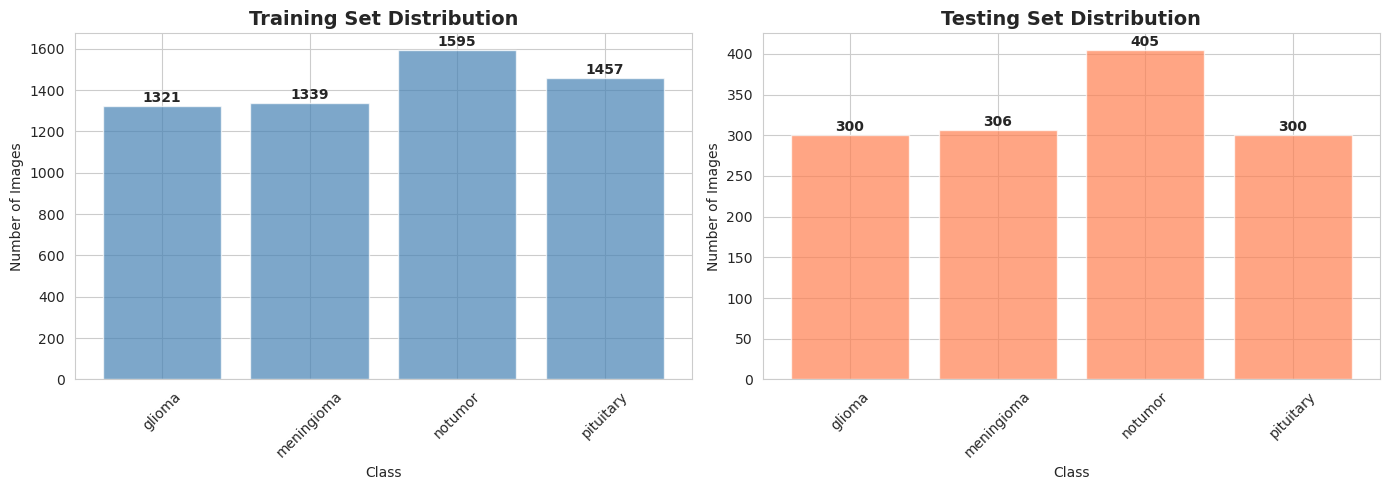

✓ Custom Dataset class defined
✓ Transforms defined

Training transforms include:
  - Random rotation (±20°)
  - Random horizontal/vertical flip
  - Color jitter
  - Random affine transformation
✓ Data loaders created

Dataset sizes:
  Training: 4569 images
  Validation: 1143 images
  Test: 1311 images

Batch size: 32
Number of batches:
  Training: 143
  Validation: 36
  Test: 41


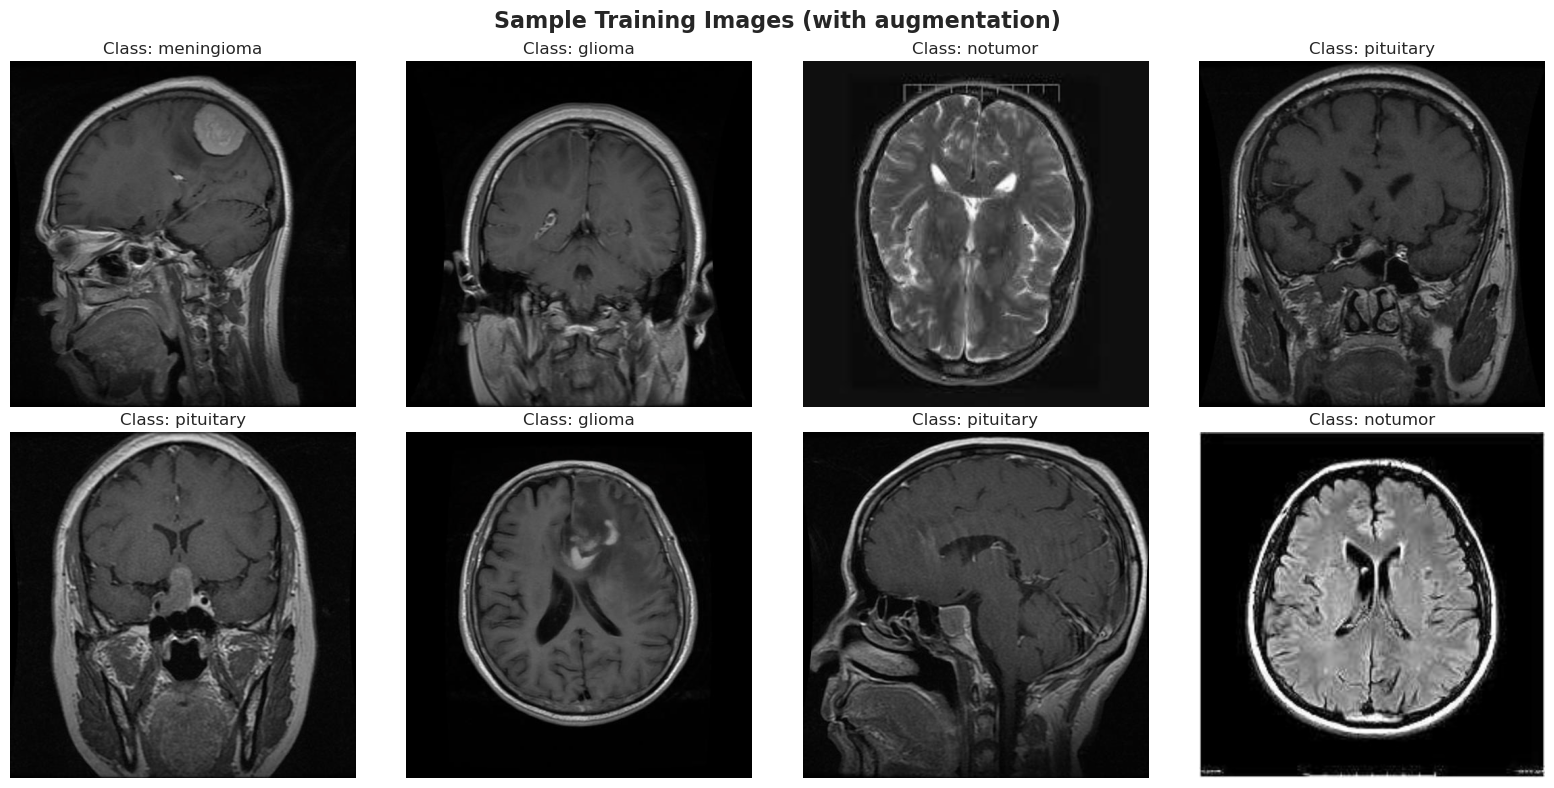

/home/23bq1a4293/.local/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/23bq1a4293/.local/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


✓ Model created

Model: ResNet50 with custom classification head
Total parameters: 24,689,476
Trainable parameters: 24,689,476
Device: cuda


In [1]:
## 2. Import Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.notebook import tqdm
import random

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

# Sklearn for metrics
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA Device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")
## 3. Configuration
# Configuration
CONFIG = {
    # Paths
    'train_dir': '/home/23bq1a4293/Personal/project/Classification_Data/Training',
    'test_dir': '/home/23bq1a4293/Personal/project/Classification_Data/Testing',
    'model_save_path': '/home/23bq1a4293/Personal/project/models/Classification/best_brain_tumor_model.pth',
    
    # Data parameters
    'img_size': 512,
    'batch_size': 32,
    'num_workers': 2,
    'val_split': 0.2,
    
    # Model parameters
    'num_classes': 4,
    'class_names': ['glioma', 'meningioma', 'notumor', 'pituitary'],
    
    # Training parameters
    'num_epochs': 50,
    'learning_rate': 0.00001,
    'patience': 10,  # Early stopping patience
    'device': torch.device('cuda' if torch.cuda.is_available() else 'cpu')
}

print("Configuration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")
## 4. Dataset Analysis
def analyze_dataset(base_dir, class_names):
    """Analyze dataset distribution and characteristics"""
    
    stats = {}
    
    for class_name in class_names:
        class_dir = os.path.join(base_dir, class_name)
        
        if os.path.exists(class_dir):
            images = [f for f in os.listdir(class_dir) 
                     if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
            stats[class_name] = len(images)
        else:
            stats[class_name] = 0
    
    return stats

# Analyze both splits
train_stats = analyze_dataset(CONFIG['train_dir'], CONFIG['class_names'])
test_stats = analyze_dataset(CONFIG['test_dir'], CONFIG['class_names'])

# Create DataFrame for visualization
df_stats = pd.DataFrame({
    'Class': CONFIG['class_names'],
    'Training': [train_stats[c] for c in CONFIG['class_names']],
    'Testing': [test_stats[c] for c in CONFIG['class_names']]
})

print("\nDataset Distribution:")
print(df_stats)
print(f"\nTotal Training: {sum(train_stats.values())}")
print(f"Total Testing: {sum(test_stats.values())}")

# Visualize distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(df_stats['Class'], df_stats['Training'], color='steelblue', alpha=0.7)
axes[0].set_title('Training Set Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Number of Images')
axes[0].tick_params(axis='x', rotation=45)
for i, v in enumerate(df_stats['Training']):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

axes[1].bar(df_stats['Class'], df_stats['Testing'], color='coral', alpha=0.7)
axes[1].set_title('Testing Set Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Number of Images')
axes[1].tick_params(axis='x', rotation=45)
for i, v in enumerate(df_stats['Testing']):
    axes[1].text(i, v + 5, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()
## 5. Custom Dataset Class
class BrainTumorDataset(Dataset):
    """Custom Dataset for Brain Tumor images"""
    
    def __init__(self, root_dir, class_names, transform=None):
        """
        Args:
            root_dir (string): Directory with class subdirectories
            class_names (list): List of class names
            transform (callable, optional): Optional transform to be applied
        """
        self.root_dir = root_dir
        self.class_names = class_names
        self.transform = transform
        self.samples = []
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(class_names)}
        
        # Load all image paths and labels
        for class_name in class_names:
            class_dir = os.path.join(root_dir, class_name)
            
            if not os.path.exists(class_dir):
                continue
            
            for img_name in os.listdir(class_dir):
                if img_name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                    img_path = os.path.join(class_dir, img_name)
                    self.samples.append((img_path, self.class_to_idx[class_name]))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        
        # Load image
        image = Image.open(img_path)
        
        # Convert grayscale to RGB
        if image.mode != 'RGB':
            image = image.convert('RGB')
        
        # Apply transforms
        if self.transform:
            image = self.transform(image)
        
        return image, label

print("✓ Custom Dataset class defined")
## 6. Data Transforms & Augmentation
# Data augmentation for training
train_transform = transforms.Compose([
    transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    transforms.RandomRotation(20),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# No augmentation for validation/test
val_test_transform = transforms.Compose([
    transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("✓ Transforms defined")
print("\nTraining transforms include:")
print("  - Random rotation (±20°)")
print("  - Random horizontal/vertical flip")
print("  - Color jitter")
print("  - Random affine transformation")
## 7. Create Data Loaders
# Create full training dataset
full_train_dataset = BrainTumorDataset(
    root_dir=CONFIG['train_dir'],
    class_names=CONFIG['class_names'],
    transform=train_transform
)

# Split into train and validation
train_size = int((1 - CONFIG['val_split']) * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = torch.utils.data.random_split(
    full_train_dataset, 
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# Update validation dataset transform
val_dataset.dataset.transform = val_test_transform

# Create test dataset
test_dataset = BrainTumorDataset(
    root_dir=CONFIG['test_dir'],
    class_names=CONFIG['class_names'],
    transform=val_test_transform
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=True,
    num_workers=CONFIG['num_workers'],
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=False,
    num_workers=CONFIG['num_workers'],
    pin_memory=True if torch.cuda.is_available() else False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=False,
    num_workers=CONFIG['num_workers'],
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"✓ Data loaders created")
print(f"\nDataset sizes:")
print(f"  Training: {len(train_dataset)} images")
print(f"  Validation: {len(val_dataset)} images")
print(f"  Test: {len(test_dataset)} images")
print(f"\nBatch size: {CONFIG['batch_size']}")
print(f"Number of batches:")
print(f"  Training: {len(train_loader)}")
print(f"  Validation: {len(val_loader)}")
print(f"  Test: {len(test_loader)}")
## 8. Visualize Sample Images
def denormalize(tensor):
    """Denormalize image tensor for visualization"""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return tensor * std + mean

# Get a batch of training data
images, labels = next(iter(train_loader))

# Plot sample images
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for i in range(8):
    img = denormalize(images[i]).permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)
    
    axes[i].imshow(img)
    axes[i].set_title(f"Class: {CONFIG['class_names'][labels[i]]}")
    axes[i].axis('off')

plt.suptitle('Sample Training Images (with augmentation)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()
## 9. Build Model (Transfer Learning)
class BrainTumorClassifier(nn.Module):
    """Transfer Learning Model with Custom Head"""
    
    def __init__(self, num_classes=4, pretrained=True):
        super(BrainTumorClassifier, self).__init__()
        
        # Load pretrained ResNet50
        self.base_model = models.resnet50(pretrained=pretrained)
        
        # Get number of features from last layer
        num_features = self.base_model.fc.in_features
        
        # Replace the final fully connected layer
        self.base_model.fc = nn.Sequential(
            nn.Linear(num_features, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x):
        return self.base_model(x)

# Create model
model = BrainTumorClassifier(num_classes=CONFIG['num_classes'])
model = model.to(CONFIG['device'])

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("✓ Model created")
print(f"\nModel: ResNet50 with custom classification head")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Device: {CONFIG['device']}")
## 10. Loss Function & Optimizer
# Loss function
criterion = nn.CrossEntropyLoss(label_smoothing =0.1)

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'])

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode='min', 
    factor=0.5, 
    patience=5
)


In [8]:
import nibabel as nib
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import os
from PIL import Image
from torchvision import transforms
from tqdm.notebook import tqdm
from skimage.exposure import match_histograms
from skimage.filters import threshold_otsu

# --- 1. SETTINGS & PATHS ---
MODEL_PATH = '/home/23bq1a4293/Personal/project/models/Classification/best_brain_tumor_model.pth'
NIFTI_PATH = '/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset/sub-001/anat/sub-001_acq-Cor_T1w.nii.gz'
REF_IMAGE_PATH = '/home/23bq1a4293/Personal/project/Classification_Data/Training/pituitary/Tr-pi_0011.jpg'

# --- 2. LOAD MODEL WITH CHECKPOINT FIX ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Re-initialize your model architecture here (assuming BrainTumorClassifier is defined)
model = BrainTumorClassifier(num_classes=4) 
checkpoint = torch.load(MODEL_PATH, map_location=device)

if 'model_state_dict' in checkpoint:
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"✓ Loaded Epoch {checkpoint['epoch']} weights (Val Acc: {checkpoint['val_acc']:.2%})")
else:
    model.load_state_dict(checkpoint)

model.to(device)
model.eval()

# --- 3. HELPER FUNCTIONS ---
def crop_and_pad_to_square(image_array):
    mask = image_array > 15 
    coords = np.argwhere(mask)
    if coords.size == 0: return image_array 
    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0) + 1
    cropped = image_array[y_min:y_max, x_min:x_max]
    h, w = cropped.shape
    max_dim = max(h, w)
    pad_top = (max_dim - h) // 2
    pad_left = (max_dim - w) // 2
    return np.pad(cropped, ((pad_top, max_dim-h-pad_top), (pad_left, max_dim-w-pad_left)), mode='constant')

# --- 4. THE INFERENCE ENGINE ---
def run_final_diagnosis(nifti_path, reference_path):
    # Load Reference for Histogram Matching
    reference_img = np.array(Image.open(reference_path).convert('L'))
    
    # Load NIfTI
    raw_img = nib.load(nifti_path)
    img = nib.as_closest_canonical(raw_img)
    data = img.get_fdata()
    
    # Orientation Detection
    is_coronal = any(x in nifti_path.lower() for x in ['cor', 'pituitary', 'pitutary'])
    total_slices = data.shape[1] if is_coronal else data.shape[2]
    mid = total_slices // 2
    indices = range(mid-30, mid+30) # Scan 60 middle slices
    
    preprocess = transforms.Compose([
        transforms.Resize((224, 224)), # Or your CONFIG['img_size']
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    cumulative_probs = torch.zeros(4).to(device)
    
    print(f"[*] Analyzing Volume: {os.path.basename(nifti_path)}")
    for s_idx in tqdm(indices):
        # Extract & Rotate
        slice_data = data[:, s_idx, :] if is_coronal else data[:, :, s_idx]
        slice_data = np.rot90(slice_data)
        
        # Normalize & Mask
        try: mask = slice_data > threshold_otsu(slice_data)
        except: mask = slice_data > slice_data.mean()
        
        brain = slice_data[mask]
        if brain.size > 0:
            low, high = np.percentile(brain, (1, 99))
            slice_data = np.clip(slice_data, low, high)
            slice_data = (slice_data - low) / (high - low)
            slice_data[~mask] = 0
            
        # Match & Square
        img_8bit = (np.clip(slice_data, 0, 1) * 255).astype(np.uint8)
        matched = match_histograms(img_8bit, reference_img)
        final_arr = crop_and_pad_to_square(matched.astype(np.uint8))
        
        # JPEG Proxy Fix
        temp_f = f"temp_{s_idx}.jpg"
        Image.fromarray(final_arr).save(temp_f, quality=95)
        pil_img = Image.open(temp_f).convert('RGB')
        
        # Predict
        input_tensor = preprocess(pil_img).unsqueeze(0).to(device)
        with torch.no_grad():
            output = model(input_tensor)
            cumulative_probs += torch.softmax(output, dim=1)[0]
        
        os.remove(temp_f)

    # --- FINAL REPORTING ---
    avg_probs = (cumulative_probs / len(indices)).cpu().numpy()
    classes = ['glioma', 'meningioma', 'notumor', 'pituitary']
    final_idx = np.argmax(avg_probs)
    
    print("\n" + "="*50)
    print("PHASE 2 MEDICAL RADIOLOGY REPORT")
    print("="*50)
    print(f"PRIMARY DIAGNOSIS: {classes[final_idx].upper()}")
    print(f"CONFIDENCE: {avg_probs[final_idx]*100:.2f}%")
    print("-" * 50)
    for i, name in enumerate(classes):
        print(f"{name.capitalize():<12}: {avg_probs[i]*100:>6.2f}%")
    print("="*50)

# Run it!
run_final_diagnosis(NIFTI_PATH, REF_IMAGE_PATH)

✓ Loaded Epoch 2 weights (Val Acc: 9466.32%)
[*] Analyzing Volume: sub-001_acq-Cor_T1w.nii.gz


  0%|          | 0/60 [00:00<?, ?it/s]

IndexError: index -24 is out of bounds for axis 1 with size 13